# Which resonant sideband train should make the Z2 hop?

Ideal, lossless simulation. Everything here can be re-run top to bottom; the slow lattice results are cached in `results/lattice_gate_cache/`, so a re-run takes about a minute.

**Answer.** Use the **symmetric 12** train: 12 pulses, signs `+ + − −` repeated, mirror-symmetric areas, every pulse at the fixed sideband scale. With the symmetric Trotter step at $h/J=1.5$ it reaches 1 % lattice gate error (all 1320 eight-photon inputs) at 12 steps in 13.3 µs. Gauss loss there is 4.7×10⁻⁵ and number loss 2.4×10⁻⁵. Today's paired train needs 24 steps and 26.0 µs for the same error, with the same Gauss loss. **Symmetric 16** gives the best conservation at 12 steps (Gauss 2.1×10⁻⁵, number 6.8×10⁻⁶) for 1.8 µs more. On one link, the CSWAP $e^{-i(\pi/4)ZX_{ab}}$ is above 99 % in 2.2–2.3 µs (symmetric 12 or 16 with 2–4 steps). The recommended step and its flat times are in Section 8.

## The model in one page

**Lattice.** 4 cavities and 3 transmons, `C1 -Q1- C2 -Q2- C3 -Q3- C4`. Link $l$ is transmon $Q_l$ between its left cavity $a$ and right cavity $b$.

$$H = J\sum_{\rm links} Z\,(a^\dagger b + b^\dagger a) \;+\; h\sum_{\rm links} X ,\qquad Z=+1 \text{ for } g .$$

$H$ conserves the total photon number and the four Gauss operators $G_i = X_{i-1}\,(-1)^{n_i}\,X_i$ (the $X$ of a missing neighbour is left out).

**One hop** $e^{-i\theta Z X_{ab}}$, $X_{ab}=a^\dagger b+b^\dagger a$, is made from resonant sideband pulses only. A pulse of area $A$ and phase $\varphi$ on leg A (transmon ↔ left cavity) or leg B (transmon ↔ right cavity) is

$$P(A,\varphi) = \exp\!\big[-iA\,(e^{i\varphi}\,c\,\sigma^+ + {\rm h.c.})\big],\qquad c = a \text{ or } b .$$

Pulses on the two legs do not commute; a train of them makes the hop through their commutator, so the hop angle grows as (pulse area)². A **train** is the list of pulses (leg, area, phase) of one hop.

**Fixed sideband scale.** All sideband pulses play at the same amplitude (same Stark shift); only the flat time changes. A pulse's area is $A = g\,(t_{\rm flat} + 5\text{ ns})$, so every pulse has $A \ge A_{\min} = g \times 5$ ns $= 0.031$ rad. $g$ is set by a 250 ns full swap: $g = (\pi/2)/250$ ns. Pulse length $= A/g + 5$ ns (flat top plus two 5 ns ramps).

**One Trotter step** of hop angle $\theta = J\,dt$ (symmetric, second order). The outer links Q1 and Q3 play together:

$$\text{step} = R_x(h\,dt)\;\text{hop}_{Q1,Q3}(\theta/2)\;\text{hop}_{Q2}(\theta)\;\text{hop}_{Q1,Q3}(\theta/2)\;R_x(h\,dt) .$$

Neighbouring half $R_x$ share one 30 ns slot, so $s$ steps use $s+1$ slots. Section 6 compares it with the plain step $R_x(2h\,dt)\,\text{hop}_{Q1,Q3}(\theta)\,\text{hop}_{Q2}(\theta)$.

**Qubit echo, always on.** From step 2 on, the $R_x$ slot also carries a π on every transmon. After an odd number of π's every leg-A pulse is played at +π; this turns the train into the hop with the opposite sign, which is what the flipped transmon needs. A net π left at the end is not played: it is accounted for at readout (no time).

**What is compared, and how.**

| | inputs | fidelity |
|---|---|---|
| one link (Sections 2–3) | 90: transmon g or e, $n_a+n_b\le 8$ | gate fidelity $F = \lvert \mathrm{Tr}(U_{\rm target}^\dagger U)\rvert^2/90^2$ |
| lattice (Sections 4–6) | all 1320 states with exactly 8 photons (165 photon arrangements × 8 transmon states) | gate fidelity $F = \lvert \mathrm{Tr}(V^\dagger P U P)\rvert^2/1320^2$, $V=e^{-iHT}$ |

Both are full unitary (gate) fidelities: they include relative phases between inputs. In the lattice every input is evolved in a space with more photons than 8, so a pulse that adds or removes a photon lowers $F$; $P$ (the 8-photon block) is applied only at the end. Lattice parameters: $JT=\pi/2$, $h/J$ = 0.5, 1.5, 3.0.

* **Photon-number loss** = probability, averaged over the 1320 inputs, that the final state no longer has 8 photons.
* **Gauss loss** = probability, averaged over the 1320 inputs, that at least one of the four $G_i$ changed.

**What is NOT simulated:** transmon f level, loss, dephasing, χ / Kerr, pulse shapes (each pulse is an ideal area), hardware calibration.

**Files.** `resonant_trains.py`: the trains, timing and one-link simulation. `lattice_gate_fidelity.py`: the lattice gate fidelity. `optimise_trains.py`: how the optimised trains were found (writes `trains/*.json`). `checks/`: independent checks of both modules. Every table is saved as `results/resonant_trains_*.csv`.

In [1]:
import os
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[name] = "1"                       # one thread per process; the runs below are parallel over processes
import json
from concurrent.futures import ProcessPoolExecutor
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import resonant_trains as rt
import lattice_gate_fidelity as lg

# ---------------- parameters ----------------
J_T = np.pi / 2                                  # total hop angle J T of the lattice evolution
H_OVER_J = [0.5, 1.5, 3.0]                       # transmon field h / J
H_MAIN = 1.5                                     # h / J used in Sections 5 and 6
TOTAL_PHOTONS = 8                                # lattice inputs: every state with exactly this many photons
STEPS = [4, 6, 8, 12, 16, 24, 32, 48]            # Trotter steps; hop angle per step theta = J_T / steps
PHI_CSWAP = np.pi / 4                            # Section 3: the single-link gate exp(-i (pi/4) Z X_ab)
K_CSWAP = [1, 2, 3, 4, 6, 8, 12, 16, 24]         # ... made from k steps of angle pi / (4 k)
TRAINS = ["textbook", "paired", "half-ends", "symmetric 8", "symmetric 12", "symmetric 16"]
COLORS = dict(zip(TRAINS, ["#7f7f7f", "#1f77b4", "#ff7f0e", "#e377c2", "#d62728", "#2ca02c"]))
CUTOFF_TOLERANCE = 1e-7                          # lattice: raise the photon cutoff until results change less than this
LINK_CUTOFF_TOLERANCE = 1e-9                     # one link: same for the cavity cutoff
CACHE = os.path.abspath("results/lattice_gate_cache")   # finished lattice results (keyed by pulses + parameters + code)
WORKERS = 24
os.makedirs("results", exist_ok=True)
print(f"g = {rt.G:.3f} rad/us, A_min = {rt.A_MIN:.4f} rad, lattice inputs = {8 * comb(TOTAL_PHOTONS + 3, 3)}")


def run_parallel(function, jobs):
    with ProcessPoolExecutor(WORKERS) as pool:
        results = list(pool.map(function, jobs))
    assert len(results) == len(jobs)
    return results


def lattice_job(train_full, train_half, steps, h_over_J, order=2, total_photons=TOTAL_PHOTONS):
    """One lattice run: inner link plays train_full (theta), outer links train_half (theta/2; order 2)."""
    return dict(train_full=train_full, train_half=train_half, steps=steps, J_t=J_T, h_over_J=h_over_J, order=order,
                total_photons=total_photons, cutoff_tolerance=CUTOFF_TOLERANCE, cache_directory=CACHE)


def flat(result):
    """A lattice result as one table row (the per-sector and cutoff-history entries stored as text)."""
    return {key: json.dumps(value) if isinstance(value, (dict, list)) else value for key, value in result.items()}

g = 6.283 rad/us, A_min = 0.0314 rad, lattice inputs = 1320


## 1. The six trains

All trains play the legs alternately **B A B A …**. "−" means the pulse phase is shifted by π. Leg B always has an extra phase of π/2 relative to leg A; that makes the hop $Z X_{ab}$ rather than $Z\,i(a^\dagger b - b^\dagger a)$.

| train | pulses | signs | areas | numbers per hop angle |
|---|---|---|---|---|
| **textbook** (today's single, W_sym) | 8 | `+ + − − − − + +` | all equal | 1 scale, calibrated |
| **paired** (today's paired) | 16 | textbook, then textbook with every sign flipped | all equal | 1 scale, calibrated |
| **half-ends** | 8 | `+ + − − + + − −` | (1,1,2,2,2,2,1,1) × scale | 1 scale, calibrated |
| **symmetric 8 / 12 / 16** | 8 / 12 / 16 | `+ + − −` repeated | mirror-symmetric, each ≥ $A_{\min}$ | 4 / 6 / 8 areas, optimised |

"Calibrated" = the one scale that gives the smallest one-link gate error against the exact hop (90 inputs). The symmetric trains' areas come from `optimise_trains.py` (Section 2). A symmetric Trotter step needs two trains per hop angle: $\theta$ for the inner link and $\theta/2$ for the outer links.

In [2]:
def build(job):
    name, theta = job
    if name == "textbook":
        return rt.textbook(rt.calibrate(rt.textbook, theta, np.sqrt(theta / 2)))
    if name == "paired":
        return rt.paired(rt.calibrate(rt.paired, theta, np.sqrt(theta / 4)))
    if name == "half-ends":
        return rt.half_ends(rt.calibrate(rt.half_ends, theta, 0.66 * np.sqrt(theta / 2)))
    return rt.symmetric(theta, int(name.split()[1]))


# every hop angle used below: lattice steps (theta and theta / 2) and the CSWAP steps pi / (4 k)
ALL_ANGLES = sorted({J_T / s for s in STEPS} | {J_T / s / 2 for s in STEPS} | {PHI_CSWAP / k for k in K_CSWAP})
build_jobs = [(name, th) for name in TRAINS for th in ALL_ANGLES
              if not (name.startswith("symmetric") and th == PHI_CSWAP)]       # no symmetric train for theta = pi/4
TRAIN = dict(zip(build_jobs, run_parallel(build, build_jobs)))                  # TRAIN[name, theta] = list of pulses
THETA_12 = J_T / 12                              # inner-link hop angle at 12 steps (pi/24 = 0.131)
print(f"{len(TRAIN)} trains built")
for name in TRAINS:
    t = TRAIN[name, THETA_12]
    print(f"{name:13s} theta = pi/24: {len(t):2d} pulses, {1e3 * rt.train_time(t):3.0f} ns, "
          f"one-hop gate error {rt.link_infidelity(t, THETA_12):.1e}")

63 trains built
textbook      theta = pi/24:  8 pulses, 386 ns, one-hop gate error 2.9e-02
paired        theta = pi/24: 16 pulses, 582 ns, one-hop gate error 2.9e-03
half-ends     theta = pi/24:  8 pulses, 367 ns, one-hop gate error 3.5e-03
symmetric 8   theta = pi/24:  8 pulses, 377 ns, one-hop gate error 6.4e-04
symmetric 12  theta = pi/24: 12 pulses, 452 ns, one-hop gate error 1.3e-04
symmetric 16  theta = pi/24: 16 pulses, 523 ns, one-hop gate error 6.0e-05


The six trains at $\theta=\pi/24$ (the inner link at 12 steps), drawn to scale. Bar length = pulse length, colour = pulse phase, number in the bar = area / $\sqrt{\theta/2}$ (the leading-order textbook area; the calibrated textbook area is 1.06 of it).

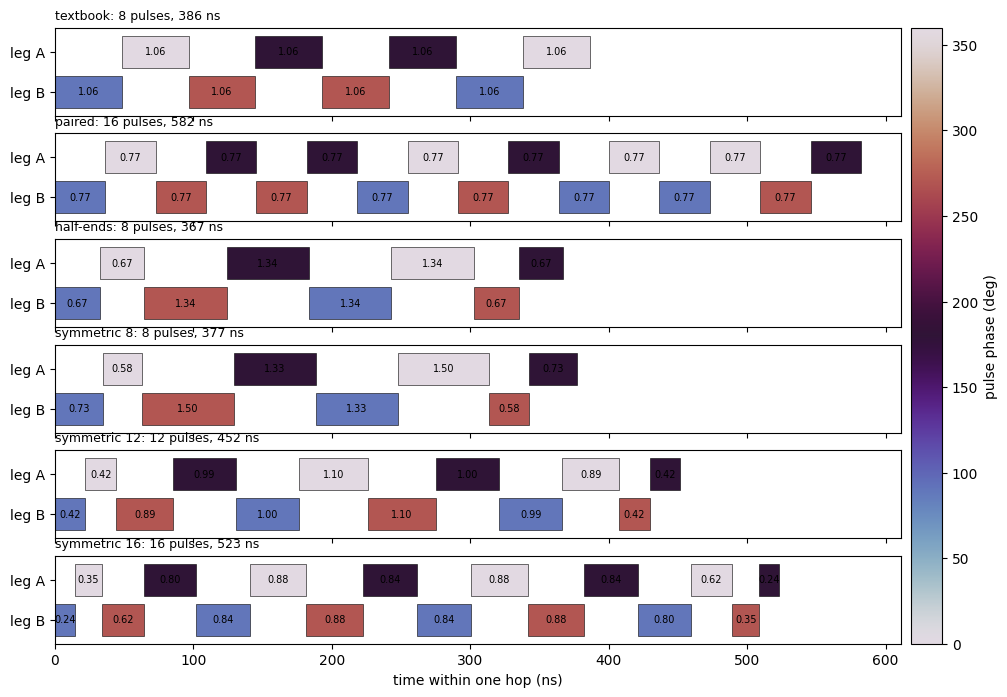

In [3]:
CMAP = plt.get_cmap("twilight")                  # cyclic colour map for phases 0 .. 360 deg


def phase_colour(phase):
    return CMAP((phase % (2 * np.pi)) / (2 * np.pi))


fig, axes = plt.subplots(len(TRAINS), 1, figsize=(13, 1.2 * len(TRAINS) + 0.8), sharex=True)
for ax, name in zip(axes, TRAINS):
    t = 0.0
    for leg, area, phase in TRAIN[name, THETA_12]:
        length = rt.pulse_length(area)
        ax.barh(f"leg {leg}", 1e3 * length, left=1e3 * t, color=phase_colour(phase), edgecolor="k", lw=0.4)
        ax.text(1e3 * (t + length / 2), f"leg {leg}", f"{area / np.sqrt(THETA_12 / 2):.2f}", ha="center", va="center", fontsize=7)
        t += length
    ax.set_ylim(-0.6, 1.6)
    ax.set_title(f"{name}: {len(TRAIN[name, THETA_12])} pulses, {1e3 * t:.0f} ns", fontsize=9, loc="left")
axes[-1].set_xlabel("time within one hop (ns)")
fig.colorbar(plt.cm.ScalarMappable(cmap=CMAP, norm=plt.Normalize(0, 360)), ax=axes, label="pulse phase (deg)", pad=0.01)
plt.show()

## 2. How the optimised trains were found

`optimise_trains.py` runs three searches. Each one changes pulse areas (and phases) to minimise

$$\text{cost} = \underbrace{1 - \big|\tfrac{1}{90}\,\mathrm{Tr}(U_{\rm exact}^\dagger U_{\rm train})\big|^2}_{\text{one-hop gate error}} \;+\; 10^{-4} \sum_i |A_i| ,$$

the gate error against the exact hop $e^{-i\theta ZX_{ab}}$ on one link (all 90 inputs), plus a small penalty on the total area so that the train stays short. It uses L-BFGS-B, a local gradient search, from several starting points, and keeps the best. Conservation is not asked for separately; it enters only because the target hop conserves photon number, so a transmon flip counts as gate error. Symmetry is not asked for in searches 1 and 2.

1. **Free search.** 8, 12 or 16 pulses on legs B A B A …, every area and every phase free, plus three virtual frame phases (a phase on the transmon and on each cavity after the train). Starts: the textbook/paired pattern with equal areas (already mirror-symmetric for 8 and 16 pulses), and 9 randomly kicked copies. Pulses that end below 10⁻³ rad are dropped and two neighbouring pulses on the same leg with the same phase are merged (same unitary).
2. **Bounded search.** The same, with every area ≥ $A_{\min}$ (what a fixed sideband scale can play), started from the best free train with all its pulses, or with its 2 or 4 smallest pulses removed.
3. **Symmetric search** (the trains used in this notebook). The shape of the best trains of searches 1 and 2 is imposed: signs `+ + − −` repeated, mirror-symmetric areas, no frame phases. Only $n/2$ areas are free, each ≥ $A_{\min}$. Run for $n$ = 8, 12, 16 at every hop angle used here, 6 starts each.

The cell below prints each search's train at $\theta=\pi/24$. Areas are given in units of $\sqrt{\theta/2}$ with the sign of the pulse (+ for the leg's first phase, − for +180°).

In [4]:
def signed_areas(train):
    """Each pulse's area, with sign + if its phase equals the first phase on the same leg and - if it is 180 deg off."""
    first, out = {}, []
    for leg, area, phase in train:
        if rt.is_pulse(leg):
            first.setdefault(leg, phase)
            out.append(area * np.cos(phase - first[leg]))
    return np.array(out)


searches = {f"1. free ({n} allowed)": rt.free_search_train(THETA_12, n) for n in (12, 16)}
searches.update({f"2. {label}": train for label, train in rt.bounded_search_trains().items() if label.startswith("inner")})
searches.update({f"3. symmetric {n}": TRAIN[f"symmetric {n}", THETA_12] for n in (8, 12, 16)})
for label, train in searches.items():
    s = signed_areas(train)
    frames = [abs(np.degrees(ph)) for leg, _, ph in train if not rt.is_pulse(leg)]
    print(f"{label:26s} {len(s):2d} pulses, {1e3 * rt.train_time(train):3.0f} ns, gate error {rt.link_infidelity(train, THETA_12):.2e}, "
          f"smallest area {np.min(np.abs(s)):.4f} rad, largest frame phase {max(frames, default=0):.2f} deg")
    print(f"{'':26s} areas: {np.round(s / np.sqrt(THETA_12 / 2), 2).tolist()}")

# every symmetric train used below obeys the fixed scale and is mirror-symmetric
for (name, th), train in TRAIN.items():
    if name.startswith("symmetric"):
        areas = np.array([area for _, area, _ in train])
        assert areas.min() >= rt.A_MIN - 1e-12 and np.allclose(areas, areas[::-1])
print(f"\nall {sum(n.startswith('symmetric') for n, _ in TRAIN)} symmetric trains: every area >= A_min = {rt.A_MIN:.4f} rad, mirror-symmetric")

1. free (12 allowed)       12 pulses, 440 ns, gate error 1.63e-04, smallest area 0.0428 rad, largest frame phase 0.06 deg
                           areas: [0.17, 0.42, -0.54, -0.96, 0.91, 1.09, -1.12, -1.06, 0.97, 0.92, -0.4, -0.41]
1. free (16 allowed)       12 pulses, 450 ns, gate error 1.27e-04, smallest area 0.1005 rad, largest frame phase 0.00 deg
                           areas: [0.39, 0.43, -0.86, -1.0, 1.0, 1.11, -1.11, -1.0, 1.0, 0.86, -0.43, -0.39]
2. inner 12, bounded       12 pulses, 452 ns, gate error 1.26e-04, smallest area 0.1067 rad, largest frame phase 0.00 deg
                           areas: [0.42, 0.42, -0.89, -0.99, 1.0, 1.1, -1.1, -1.0, 0.99, 0.89, -0.42, -0.42]
2. inner 10, bounded       10 pulses, 405 ns, gate error 2.23e-04, smallest area 0.1150 rad, largest frame phase 0.00 deg
                           areas: [0.45, 0.49, -1.04, -1.14, 1.24, 1.24, -1.14, -1.04, 0.49, 0.45]
2. inner 8, bounded         8 pulses, 377 ns, gate error 6.38e-04, smallest area 0.

**What the searches found** ($\theta=\pi/24$):

* **Free search, 16 pulses allowed.** The best of the 10 starts is the unkicked one (paired pattern, equal areas, already mirror-symmetric). It sets two pulses to zero; after merging the neighbours that then sit on the same leg, it is a 12-pulse train with sign pattern `+ + − −` repeated, mirror-symmetric areas, 0°/180° phases and zero frame phases: gate error 1.27×10⁻⁴ in 450 ns. The 9 randomly kicked starts end less symmetric and worse (1.29–6.4×10⁻⁴).
* **Free search, 12 pulses allowed.** Its start is not symmetric; the best result is asymmetric and worse: 1.63×10⁻⁴.
* **Bounded search** (every area ≥ $A_{\min}$), started from the 12-pulse free train: same error, 1.26×10⁻⁴ in 452 ns. With the 2 or 4 smallest pulses removed: 2.2×10⁻⁴ (10 pulses), 6.4×10⁻⁴ (8 pulses).
* **Symmetric search**, with the `+ + − −`, mirror-symmetric shape imposed: the same 12-pulse train as the bounded search (areas equal to 2×10⁻⁵ rad), and the same 8-pulse one. With 16 pulses it is 2× better (6.0×10⁻⁵) and 71 ns longer.

So the best trains found are mirror-symmetric, and imposing the shape reduces 27 free numbers (12 areas, 12 phases, 3 frame phases) to 6 areas and beats the free 12-pulse search. This is the best of the starts tried, not a proof that symmetry is optimal.

### Why a train can make the hop, and where its error goes

Write a train as one exponential, $U = \exp[-i(\Omega_1 + \Omega_2 + \Omega_3 + \dots)]$, where $\Omega_m$ is of order (pulse area)$^m$ (Magnus expansion).

* $\Omega_1$ = the summed signed area on each leg. It flips the transmon, so a good train makes it zero. In textbook, paired and half-ends the + and − pulses on each leg cancel exactly. The optimised symmetric trains keep a small residual (per leg at $\theta=\pi/24$: 4.5×10⁻³ rad for symmetric 8, 6.3×10⁻⁴ for symmetric 12, 9.7×10⁻⁵ for symmetric 16; computed in the cell below), because the optimiser trades it against higher orders.
* $\Omega_2$ contains the commutator of the two legs, $[K_A, K_B] \propto Z(a^\dagger b + b^\dagger a)$: this is the hop.
* Odd orders ($\Omega_3, \Omega_5, \dots$) flip the transmon, i.e. move a photon into or out of it: **photon-number loss**, and also Gauss loss.
* Even orders keep the photon number but distort the hop; that is a gate error and can still change a Gauss eigenvalue.

For a fixed pattern with all areas scaled by $\lambda$, the transmon-flipping part starts at order $\lambda^3$ for half-ends, $\lambda^5$ for textbook ($\Omega_3$ cancels) and $\lambda^7$ for paired. The cell below checks this: it takes $\log U$ of each pattern at small $\lambda$ and fits how its transmon-flipping part scales. The optimised symmetric trains are re-optimised at every angle, so they do not have one fixed scaling; the plot below shows how their error and transmon flip fall with the angle.

In [5]:
from scipy.linalg import expm, logm

# Omega_1 residual: summed signed area per leg (0 for textbook, paired, half-ends by construction)
for name in TRAINS:
    s, legs = signed_areas(TRAIN[name, THETA_12]), [leg for leg, _, _ in TRAIN[name, THETA_12]]
    print(f"{name:13s} theta = pi/24: signed area sum, leg A {sum(x for x, l in zip(s, legs) if l == 'A'):+.1e} rad, "
          f"leg B {sum(x for x, l in zip(s, legs) if l == 'B'):+.1e} rad")

# order of the transmon-flipping part of log U for a fixed pattern with every area = lam (small space: <= 3 photons)
L = 4                                                    # cavity levels
a1 = np.diag(np.sqrt(np.arange(1, L)), 1)
sigma_plus = np.array([[0, 0], [1, 0]])
c = {"A": np.kron(np.kron(sigma_plus, a1), np.eye(L)), "B": np.kron(np.kron(sigma_plus, np.eye(L)), a1)}
n_total = np.add.outer(np.arange(L), np.arange(L)).ravel()
keep = np.concatenate([n_total <= 2, n_total <= 2])      # g with <= 2 photons, e with <= 2 photons: away from the cutoff
flips = np.zeros((2 * L * L, 2 * L * L), bool)
flips[:L * L, L * L:] = flips[L * L:, :L * L] = True     # matrix elements between g and e


def flip_part(pattern, lam):
    U = np.eye(2 * L * L, dtype=complex)
    for leg, area, phase in pattern:
        h = np.exp(1j * phase) * c[leg]                  # e^{i phi} c sigma+
        U = expm(-1j * lam * area * (h + h.conj().T)) @ U
    generator = 1j * logm(U)
    return np.linalg.norm(np.where(flips, generator, 0)[np.ix_(keep, keep)])


for name, make in (("textbook", rt.textbook), ("paired", rt.paired), ("half-ends", rt.half_ends)):
    lams = np.array([0.02, 0.04, 0.08])
    values = [flip_part(make(1.0), lam) for lam in lams]
    print(f"{name:10s} transmon-flip part of log U grows as lambda^{np.polyfit(np.log(lams), np.log(values), 1)[0]:.2f}")

textbook      theta = pi/24: signed area sum, leg A +0.0e+00 rad, leg B +0.0e+00 rad
paired        theta = pi/24: signed area sum, leg A +0.0e+00 rad, leg B +0.0e+00 rad
half-ends     theta = pi/24: signed area sum, leg A +0.0e+00 rad, leg B +0.0e+00 rad
symmetric 8   theta = pi/24: signed area sum, leg A +4.5e-03 rad, leg B -4.5e-03 rad
symmetric 12  theta = pi/24: signed area sum, leg A +6.3e-04 rad, leg B -6.3e-04 rad
symmetric 16  theta = pi/24: signed area sum, leg A +9.7e-05 rad, leg B -9.7e-05 rad
textbook   transmon-flip part of log U grows as lambda^4.99
paired     transmon-flip part of log U grows as lambda^6.98


half-ends  transmon-flip part of log U grows as lambda^3.02


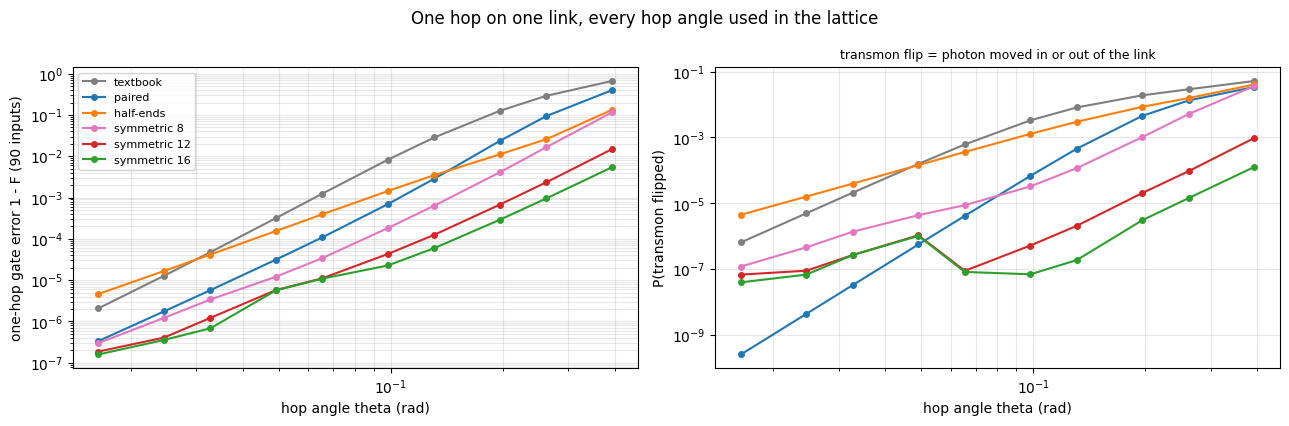

       train    theta  pulses  time_ns  gate_error  transmon_flip
    textbook 1.31e-01       8 3.86e+02    2.86e-02       8.16e-03
      paired 1.31e-01      16 5.82e+02    2.87e-03       4.58e-04
   half-ends 1.31e-01       8 3.67e+02    3.50e-03       3.01e-03
 symmetric 8 1.31e-01       8 3.77e+02    6.38e-04       1.17e-04
symmetric 12 1.31e-01      12 4.52e+02    1.26e-04       2.09e-06
symmetric 16 1.31e-01      16 5.23e+02    5.97e-05       1.90e-07


In [6]:
rows = []
for name in TRAINS:
    for th in sorted({J_T / s for s in STEPS} | {J_T / s / 2 for s in STEPS}):
        t = TRAIN[name, th]
        rows.append(dict(train=name, theta=th, pulses=len(t), time_ns=1e3 * rt.train_time(t),
                         gate_error=rt.link_infidelity(t, th), transmon_flip=rt.link_transmon_flip(t)))
one_hop = pd.DataFrame(rows)
one_hop.to_csv("results/resonant_trains_one_hop.csv", index=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
for name in TRAINS:
    d = one_hop[one_hop.train == name]
    ax1.plot(d.theta, d.gate_error, "o-", color=COLORS[name], label=name, ms=4)
    ax2.plot(d.theta, d.transmon_flip, "o-", color=COLORS[name], label=name, ms=4)
ax1.set_ylabel("one-hop gate error 1 - F (90 inputs)")
ax2.set_ylabel("P(transmon flipped)")
ax2.set_title("transmon flip = photon moved in or out of the link", fontsize=9)
for ax in (ax1, ax2):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(alpha=0.3, which="both")
    ax.set_xlabel("hop angle theta (rad)")
ax1.legend(fontsize=8)
fig.suptitle("One hop on one link, every hop angle used in the lattice")
fig.tight_layout(); plt.show()
print(one_hop[one_hop.theta.round(4) == round(THETA_12, 4)].to_string(index=False, float_format=lambda v: f"{v:.2e}"))

**Reading.** At $\theta=0.131$ (the inner link at 12 steps), one hop has gate error 2.9×10⁻² (textbook), 2.9×10⁻³ (paired), 3.5×10⁻³ (half-ends), 6.4×10⁻⁴ (symmetric 8), 1.3×10⁻⁴ (symmetric 12) and 6.0×10⁻⁵ (symmetric 16).

What matters for conservation is the right panel. A transmon flip is a photon moved into or out of the transmon, which in the lattice shows up as photon-number and Gauss loss. As a share of the gate error, the flip is 86 % for half-ends, 29 % for textbook, 18 % for symmetric 8, 16 % for paired, but only 1.7 % for symmetric 12 and 0.3 % for symmetric 16. Almost all of their small error is a slightly wrong hop, which costs fidelity but not conservation.

## 3. One link: the CSWAP $e^{-i(\pi/4) Z X_{ab}}$

Take the lattice with $h=0$ and look at one link. $k$ Trotter steps with $\theta = \pi/(4k)$ give $e^{-i(\pi/4) Z X_{ab}}$. Each step is the echo π (from step 2 on, 30 ns), then that link's hops:

* **inner pattern** (how Q2 plays it): one train of $\theta$ per step;
* **outer pattern** (how Q1, Q3 play it): two trains of $\theta/2$ per step.

On one link all hops have the same generator, so splitting the gate into $k$ steps adds no Trotter error. The error comes only from the trains. More steps means smaller angles, so each train is more accurate, but there are more of them and the gate gets longer.

Gate time: inner $k\,t(\theta) + (k-1)\times 30$ ns, outer $2k\,t(\theta/2) + (k-1)\times 30$ ns. Gate error over the 90 inputs; the cavity cutoff is raised automatically until the result no longer changes (echoes between trains can push a state above 9 photons).

The first two steps of symmetric 12 with $k=4$, inner pattern (leg A changes colour in step 2: it is played at +π after the echo):

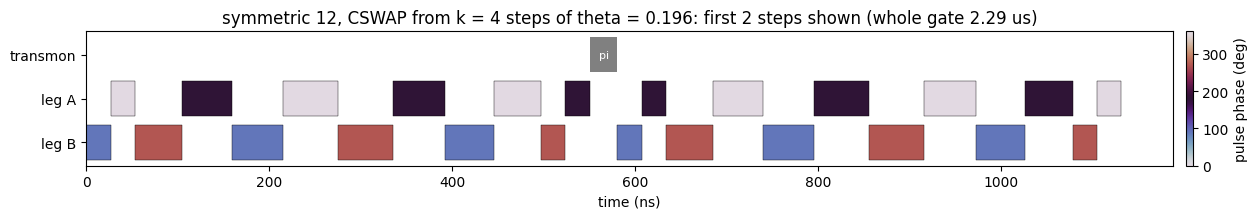

In [7]:
def draw_cswap(name, k, steps_shown=2):
    theta = PHI_CSWAP / k
    fig, ax = plt.subplots(figsize=(14, 2.3))
    t = 0.0
    for step in range(steps_shown):
        if step >= 1:
            ax.barh("transmon", 1e3 * rt.PI_PULSE, left=1e3 * t, color="0.5")
            ax.text(1e3 * (t + rt.PI_PULSE / 2), "transmon", "pi", ha="center", va="center", fontsize=8, color="w")
            t += rt.PI_PULSE
        for leg, area, phase in TRAIN[name, theta]:
            phase = phase + (np.pi if (step % 2 == 1 and leg == "A") else 0.0)
            length = rt.pulse_length(area)
            ax.barh(f"leg {leg}", 1e3 * length, left=1e3 * t, color=phase_colour(phase), edgecolor="k", lw=0.3)
            t += length
    ax.set_xlabel("time (ns)")
    total = k * rt.train_time(TRAIN[name, theta]) + (k - 1) * rt.PI_PULSE
    ax.set_title(f"{name}, CSWAP from k = {k} steps of theta = {theta:.3f}: first {steps_shown} steps shown (whole gate {total:.2f} us)")
    fig.colorbar(plt.cm.ScalarMappable(cmap=CMAP, norm=plt.Normalize(0, 360)), ax=ax, label="pulse phase (deg)", pad=0.01)
    fig.tight_layout(); plt.show()


draw_cswap("symmetric 12", 4)

105 CSWAP gates, 90 inputs each, cavity levels used [12, 14, 16]. Control: exact hops in the same sequences give gate error 0.0e+00


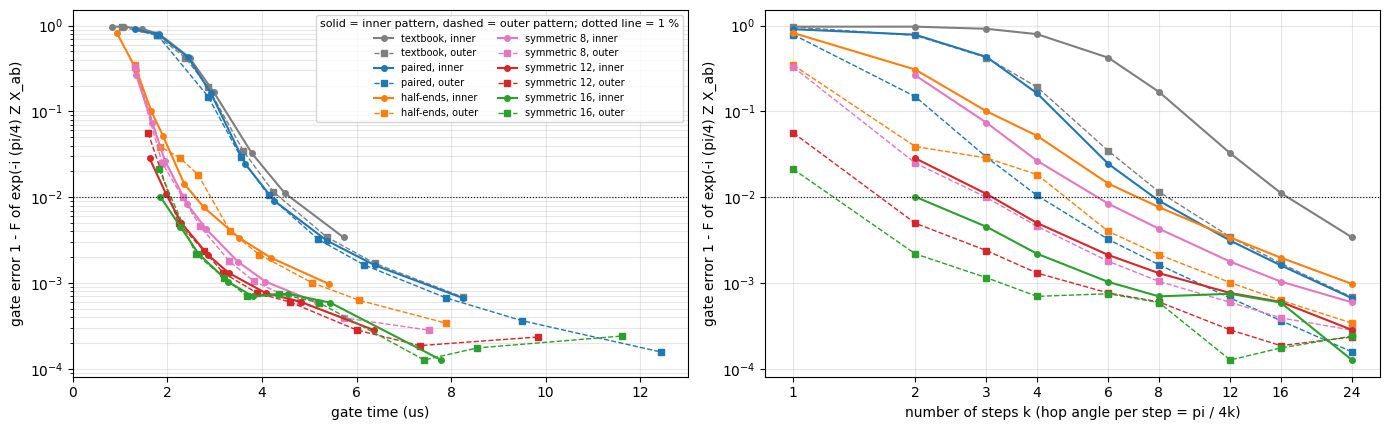


inner pattern: gate error in gate time  ('-': no symmetric train for theta = pi/4)
              textbook              paired           half-ends         symmetric 8        symmetric 12        symmetric 16
k                                                                                                                         
1   9.7e-01 in 0.82 us  9.1e-01 in 1.31 us  8.2e-01 in 0.93 us                   -                   -                   -
2   9.7e-01 in 1.07 us  7.8e-01 in 1.81 us  3.1e-01 in 1.34 us  2.6e-01 in 1.34 us  2.8e-02 in 1.62 us  1.0e-02 in 1.85 us
3   9.2e-01 in 1.46 us  4.3e-01 in 2.43 us  1.0e-01 in 1.66 us  7.4e-02 in 1.68 us  1.1e-02 in 1.97 us  4.5e-03 in 2.27 us
4   7.9e-01 in 1.83 us  1.6e-01 in 2.92 us  5.2e-02 in 1.91 us  2.7e-02 in 1.95 us  5.0e-03 in 2.29 us  2.2e-03 in 2.66 us
6   4.2e-01 in 2.47 us  2.4e-02 in 3.64 us  1.4e-02 in 2.35 us  8.4e-03 in 2.41 us  2.1e-03 in 2.86 us  1.0e-03 in 3.29 us
8   1.7e-01 in 2.98 us  9.1e-03 in 4.26 us  7.7e-03 in 

In [8]:
def cswap_job(job):
    name, k, pattern = job
    theta = PHI_CSWAP / k
    trains = [TRAIN[name, theta]] if pattern == "inner" else [TRAIN[name, theta / 2]] * 2
    return rt.cswap_gate_metrics(trains, k, PHI_CSWAP, cutoff_tolerance=LINK_CUTOFF_TOLERANCE)


def cswap_time(name, k, pattern):
    theta = PHI_CSWAP / k
    per_step = rt.train_time(TRAIN[name, theta]) if pattern == "inner" else 2 * rt.train_time(TRAIN[name, theta / 2])
    return k * per_step + (k - 1) * rt.PI_PULSE


cs_jobs = [(name, k, pattern) for name in TRAINS for k in K_CSWAP for pattern in ("inner", "outer")
           if (name, PHI_CSWAP / k / (2 if pattern == "outer" else 1)) in TRAIN]
cswap = pd.DataFrame([dict(train=name, k=k, pattern=pattern, time_us=cswap_time(name, k, pattern), **flat(result))
                      for (name, k, pattern), result in zip(cs_jobs, run_parallel(cswap_job, cs_jobs))])
assert (cswap.link_inputs_compared == 90).all() and (cswap.link_cutoff_max_change <= LINK_CUTOFF_TOLERANCE).all()
cswap.to_csv("results/resonant_trains_cswap.csv", index=False)
exact = max(rt.cswap_gate_metrics(["exact"] * n, k, PHI_CSWAP)["infidelity"] for k in K_CSWAP for n in (1, 2))
print(f"{len(cswap)} CSWAP gates, 90 inputs each, cavity levels used {sorted(cswap.link_cavity_levels.unique())}. "
      f"Control: exact hops in the same sequences give gate error {exact:.1e}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4))
for name in TRAINS:
    for pattern, style in (("inner", "o-"), ("outer", "s--")):
        d = cswap[(cswap.train == name) & (cswap.pattern == pattern)]
        ax1.plot(d.time_us, d.infidelity, style, color=COLORS[name], label=f"{name}, {pattern}", ms=4, lw=1.5 if pattern == "inner" else 1)
        ax2.plot(d.k, d.infidelity, style, color=COLORS[name], ms=4, lw=1.5 if pattern == "inner" else 1)
for ax in (ax1, ax2):
    ax.set_yscale("log"); ax.grid(alpha=0.3, which="both")
    ax.set_ylabel("gate error 1 - F of exp(-i (pi/4) Z X_ab)")
ax1.axhline(0.01, color="k", lw=0.8, ls=":")
ax2.axhline(0.01, color="k", lw=0.8, ls=":")
ax1.set_xlabel("gate time (us)"); ax1.set_xlim(0, 13)
ax2.set_xlabel("number of steps k (hop angle per step = pi / 4k)")
ax2.set_xscale("log"); ax2.set_xticks(K_CSWAP); ax2.set_xticklabels([str(k) for k in K_CSWAP]); ax2.minorticks_off()
ax1.legend(fontsize=7, ncol=2, title="solid = inner pattern, dashed = outer pattern; dotted line = 1 %", title_fontsize=8)
fig.tight_layout(); plt.show()
for pattern in ("inner", "outer"):
    d = cswap[cswap.pattern == pattern]
    error = d.pivot(index="k", columns="train", values="infidelity")[TRAINS]
    time = d.pivot(index="k", columns="train", values="time_us")[TRAINS]
    table = pd.DataFrame({name: [f"{e:.1e} in {t:.2f} us" if e == e else "-" for e, t in zip(error[name], time[name])]
                          for name in TRAINS}, index=error.index)            # e == e is False for a missing entry (NaN)
    print(f"\n{pattern} pattern: gate error in gate time  ('-': no symmetric train for theta = pi/4)")
    print(table.to_string())

**Reading.**

* **Above 99 %:** symmetric 16 with 3 steps (4.5×10⁻³ in 2.27 µs) or symmetric 12 with 4 steps (5.0×10⁻³ in 2.29 µs). Paired needs 8 steps (9.1×10⁻³ in 4.26 µs), textbook 24 steps (3.4×10⁻³ in 5.72 µs).
* **99.9 %:** symmetric 16, outer pattern with 4 steps (7.0×10⁻⁴ in 3.68 µs). Inner with 6 steps gives 1.03×10⁻³ in 3.29 µs, just short.
* With exact hops the same sequences have zero error. This checks the echo bookkeeping; it is also why on one link there is no Trotter error, only train error.
* The outer pattern with $k$ steps plays as many trains as the inner pattern with $2k$ and gives similar errors (symmetric 12: outer $k=2$, 5.0×10⁻³ in 2.23 µs; inner $k=4$, 5.0×10⁻³ in 2.29 µs).
* Beyond about 8 steps the improvement slows. At small angles the optimiser's area penalty ($10^{-4}\times$ total area) is larger than the train's gate error, so the optimiser accepts a little more error for a shorter train; more hops also accumulate more error.

## 4. The Z2 lattice: gate error, Gauss's law and photon number against total time

Every point evolves all 1320 eight-photon inputs through the whole sequence and compares with $e^{-iHT}$. Total time includes the $s+1$ R_x slots. The black dashed line is the same Trotter sequence with **exact** hops (no train error), drawn at paired's times; it is a reference, not a floor (train errors can partly cancel Trotter error).

Each lattice result is computed at a growing photon cutoff (11, 13, …) until gate error, Gauss loss, number loss and each Gauss sector's error change by less than $10^{-7}$.

order 2: 144 lattice runs x 1320 inputs; photon cutoffs used [13, 15, 17]


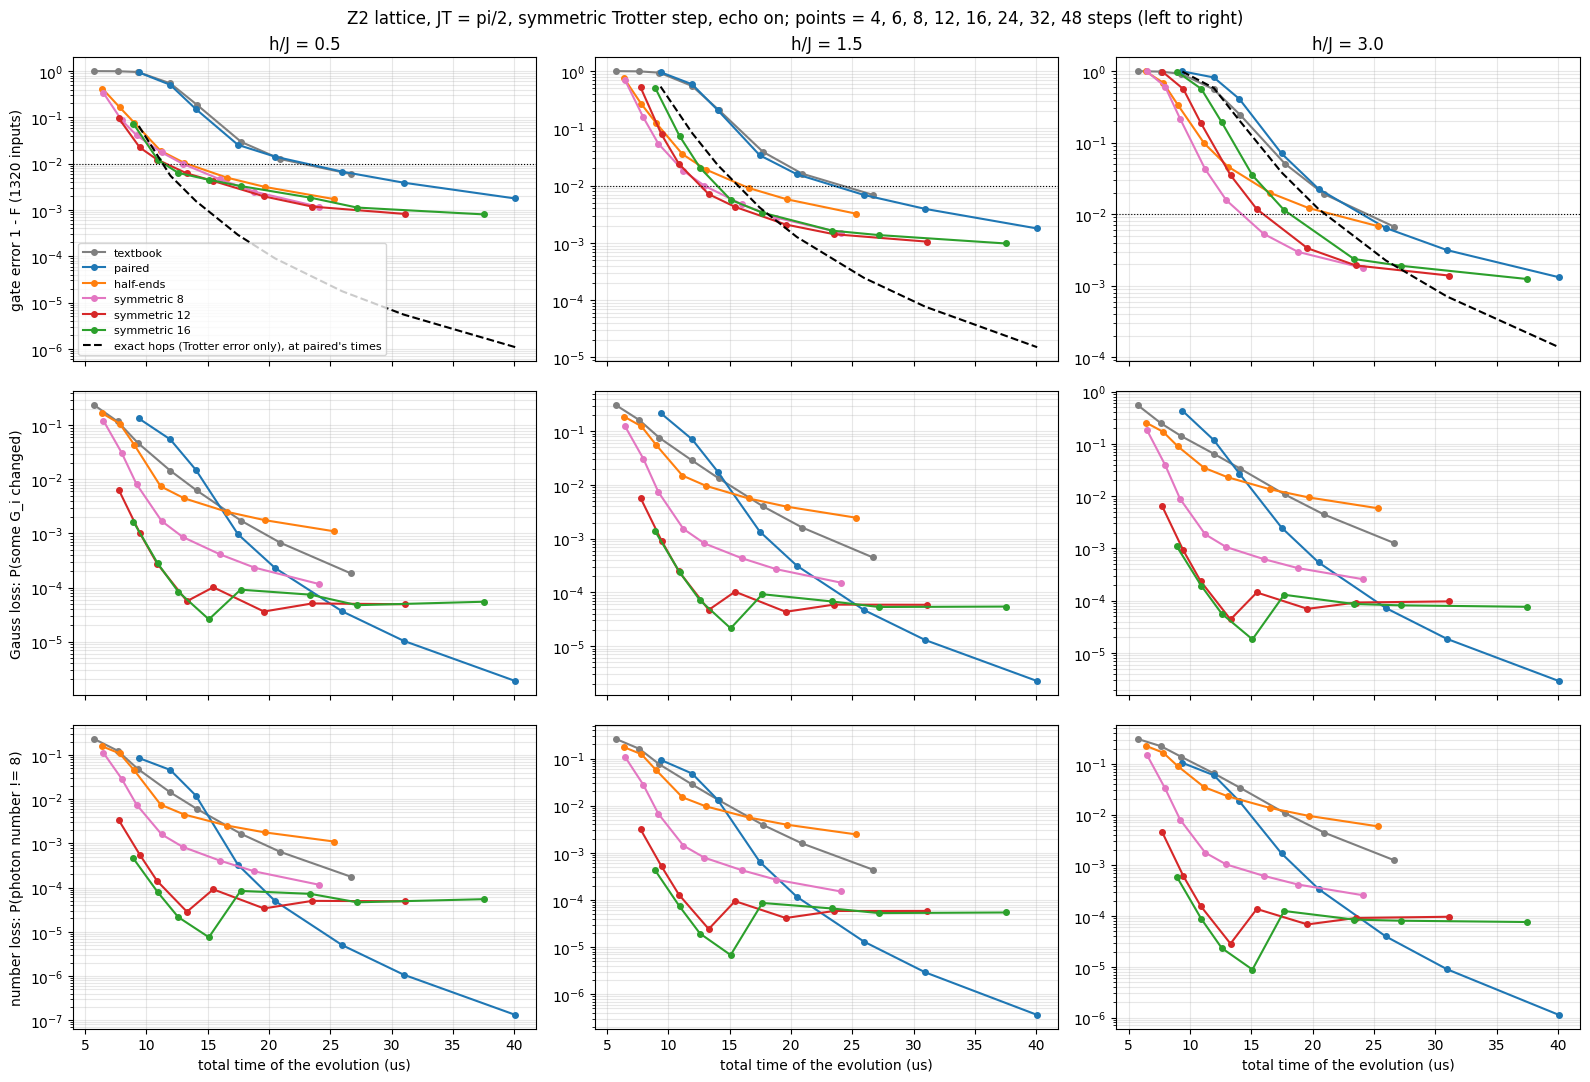

       train  steps  time_us  infidelity  gauss_lost  number_lost  exact_hop_error
    textbook     12 1.19e+01    5.52e-01    2.87e-02     2.83e-02         4.14e-03
    textbook     24 1.77e+01    3.89e-02    3.99e-03     3.90e-03         2.45e-04
      paired     12 1.75e+01    3.40e-02    1.36e-03     6.43e-04         4.14e-03
      paired     24 2.60e+01    6.88e-03    4.68e-05     1.30e-05         2.45e-04
   half-ends     12 1.12e+01    3.56e-02    1.50e-02     1.50e-02         4.14e-03
   half-ends     24 1.66e+01    9.12e-03    5.61e-03     5.62e-03         2.45e-04
 symmetric 8     12 1.12e+01    1.82e-02    1.52e-03     1.42e-03         4.14e-03
 symmetric 8     24 1.60e+01    4.73e-03    4.32e-04     4.27e-04         2.45e-04
symmetric 12     12 1.33e+01    7.10e-03    4.72e-05     2.42e-05         4.14e-03
symmetric 12     24 1.96e+01    2.10e-03    4.34e-05     4.15e-05         2.45e-04
symmetric 16     12 1.51e+01    5.67e-03    2.14e-05     6.80e-06         4.14e-03
symm

In [9]:
def lattice_runs(order, h_list):
    """Every train at every number of steps and every h/J in h_list."""
    jobs, labels = [], []
    for name in TRAINS:
        for steps in STEPS:
            full, half = TRAIN[name, J_T / steps], TRAIN[name, J_T / steps / 2]
            for h in h_list:
                jobs.append(lattice_job(full, half, steps, h, order))
                labels.append(dict(train=name, order=order, h_over_J=h, steps=steps, time_us=rt.lattice_time(full, half, order, steps)))
    out = pd.DataFrame([{**label, **flat(result)} for label, result in zip(labels, run_parallel(lg.run_lattice_gate, jobs))])
    assert (out.inputs_compared == 1320).all() and out.cutoff_converged.all() and (out.cutoff_max_change <= CUTOFF_TOLERANCE).all()
    print(f"order {order}: {len(out)} lattice runs x 1320 inputs; photon cutoffs used {sorted(out.photon_cutoff.unique())}")
    return out


exact_jobs = [lattice_job(None, None, steps, h, order) for order in (1, 2) for h in H_OVER_J for steps in STEPS]
exact_hops = pd.DataFrame([{**{k: job[k] for k in ("order", "h_over_J", "steps")}, **result}
                           for job, result in zip(exact_jobs, run_parallel(lg.exact_trotter_metrics, exact_jobs))])
EXACT = exact_hops.set_index(["order", "h_over_J", "steps"]).infidelity

lattice = lattice_runs(2, H_OVER_J)
lattice["exact_hop_error"] = [EXACT[2, h, s] for h, s in zip(lattice.h_over_J, lattice.steps)]
lattice.to_csv("results/resonant_trains_lattice.csv", index=False)

fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True)
for column, h in enumerate(H_OVER_J):
    for name in TRAINS:
        d = lattice[(lattice.train == name) & (lattice.h_over_J == h)]
        for row, metric in enumerate(("infidelity", "gauss_lost", "number_lost")):
            axes[row, column].plot(d.time_us, d[metric], "o-", color=COLORS[name], label=name, ms=4)
    ref = lattice[(lattice.train == "paired") & (lattice.h_over_J == h)]
    axes[0, column].plot(ref.time_us, ref.exact_hop_error, "k--", label="exact hops (Trotter error only), at paired's times")
    axes[0, column].axhline(0.01, color="k", lw=0.8, ls=":")
    axes[0, column].set_title(f"h/J = {h}")
for ax, label in zip(axes[:, 0], ("gate error 1 - F (1320 inputs)", "Gauss loss: P(some G_i changed)", "number loss: P(photon number != 8)")):
    ax.set_ylabel(label)
for ax in axes.flat:
    ax.set_yscale("log"); ax.grid(alpha=0.3, which="both")
for ax in axes[-1]:
    ax.set_xlabel("total time of the evolution (us)")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Z2 lattice, JT = pi/2, symmetric Trotter step, echo on; points = 4, 6, 8, 12, 16, 24, 32, 48 steps (left to right)")
fig.tight_layout(); plt.show()
cols = ["train", "steps", "time_us", "infidelity", "gauss_lost", "number_lost", "exact_hop_error"]
print(lattice[(lattice.h_over_J == H_MAIN) & lattice.steps.isin([12, 24])][cols].to_string(index=False, float_format=lambda v: f"{v:.2e}"))

**Reading** ($h/J = 1.5$, table above):

* **1 % gate error:** symmetric 12 at 12 steps (7.1×10⁻³ in 13.3 µs) and symmetric 16 at 12 steps (5.7×10⁻³ in 15.1 µs). Paired needs 24 steps (6.9×10⁻³ in 26.0 µs); textbook needs 48 steps.
* **Conservation at those points:** Gauss loss 4.7×10⁻⁵ (symmetric 12), 2.1×10⁻⁵ (symmetric 16), 4.7×10⁻⁵ (paired); number loss 2.4×10⁻⁵, 6.8×10⁻⁶, 1.3×10⁻⁵. Half-ends reaches 1 % at 24 steps but loses 5.6×10⁻³ to both, because its error is mostly transmon flip (one-hop reading above).
* **Trotter vs train error:** with exact hops, 12 steps already give 4.1×10⁻³ (pure Trotter error), against 7.1×10⁻³ for symmetric 12. The two errors do not simply add, but Trotter error is a large part.
* **A limit of the symmetric trains:** their Gauss loss stops falling beyond 12 steps (symmetric 12: 4.7×10⁻⁵ at 12, 1.0×10⁻⁴ at 16, 5.9×10⁻⁵ at 48 steps), while paired keeps falling (1.3×10⁻⁵ at 32, 2×10⁻⁶ at 48 steps, 40 µs). For Gauss loss below ~10⁻⁵, paired is still the train to use.
* For a leaky train, Gauss loss ≈ number loss (one flip changes both). At 12 steps the symmetric trains have Gauss loss 2–3 times the number loss (part of it is a phase error that keeps the photon number); beyond 12 steps the two are about equal.

### Does the error depend on the Gauss sector or on the photon number?

The 1320 inputs split into 8 Gauss sectors of 165 states each (the four $G_i = \pm1$, with $G_1G_2G_3G_4$ fixed by the photon-number parity). Below: the gate error inside each sector at the operating points, then the same trains (not re-optimised) with 2, 3, 4 and 8 photons ($8\binom{N+3}{3}$ = 80, 160, 280, 1320 inputs).

gate error inside each Gauss sector (165 inputs each), h/J = 1.5
train             paired, 24 steps  symmetric 12, 12 steps  symmetric 16, 12 steps
sector                                                                            
G = (+, +, +, +)          7.22e-03                7.57e-03                5.95e-03
G = (+, +, -, -)          6.85e-03                7.07e-03                5.65e-03
G = (+, -, +, -)          6.85e-03                7.07e-03                5.65e-03
G = (+, -, -, +)          6.61e-03                6.70e-03                5.41e-03
G = (-, +, +, -)          7.22e-03                7.57e-03                5.95e-03
G = (-, +, -, +)          6.85e-03                7.07e-03                5.65e-03
G = (-, -, +, +)          6.85e-03                7.07e-03                5.65e-03
G = (-, -, -, -)          6.61e-03                6.70e-03                5.41e-03


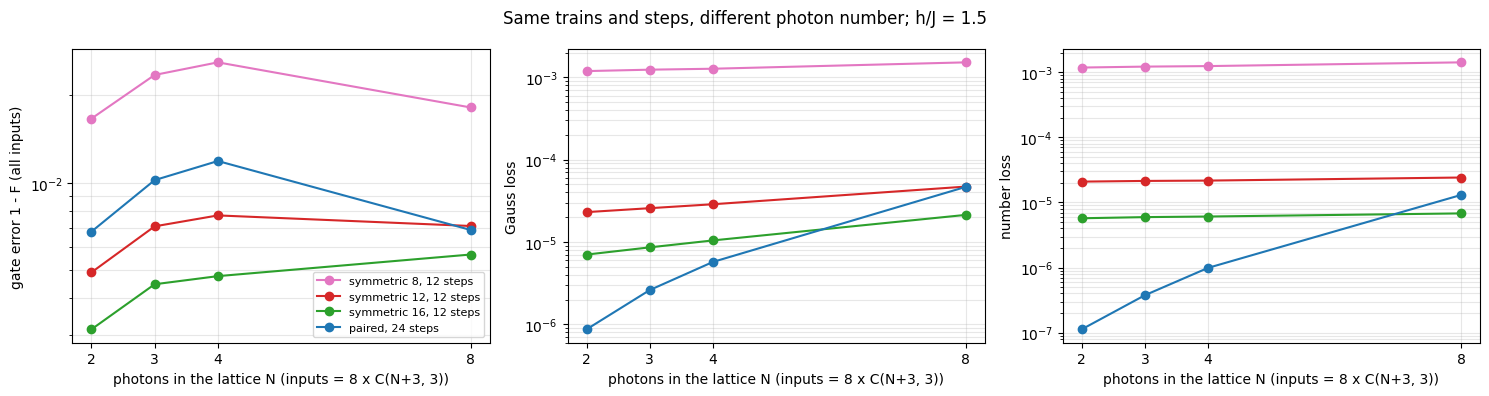

In [10]:
OPERATING = {"paired": 24, "symmetric 12": 12, "symmetric 16": 12}       # train: number of steps
rows = []
for name, steps in OPERATING.items():
    r = lattice[(lattice.train == name) & (lattice.steps == steps) & (lattice.h_over_J == H_MAIN)].iloc[0]
    for code, error in json.loads(r.gauss_sector_infidelities).items():
        signs = "".join("-" if int(code) & (1 << site) else "+" for site in range(4))
        rows.append(dict(train=f"{name}, {steps} steps", sector=f"G = ({', '.join(signs)})", gate_error=error))
sectors = pd.DataFrame(rows).pivot(index="sector", columns="train", values="gate_error")
sectors.to_csv("results/resonant_trains_gauss_sectors.csv")
print("gate error inside each Gauss sector (165 inputs each), h/J = 1.5")
print(sectors.to_string(float_format=lambda v: f"{v:.2e}"))

PHOTONS = [2, 3, 4, 8]
PHOTON_TRAINS = {"symmetric 8": 12, "symmetric 12": 12, "symmetric 16": 12, "paired": 24}
jobs, labels = [], []
for total in PHOTONS:
    for name, steps in PHOTON_TRAINS.items():
        jobs.append(lattice_job(TRAIN[name, J_T / steps], TRAIN[name, J_T / steps / 2], steps, H_MAIN, total_photons=total))
        labels.append(dict(train=name, steps=steps, total_photons=total))
photons = pd.DataFrame([{**label, **flat(result)} for label, result in zip(labels, run_parallel(lg.run_lattice_gate, jobs))])
assert all(r.inputs_compared == 8 * comb(r.total_photons + 3, 3) for r in photons.itertuples()) and photons.cutoff_converged.all()
photons.to_csv("results/resonant_trains_photon_number.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name in PHOTON_TRAINS:
    d = photons[photons.train == name].sort_values("total_photons")
    for ax, metric in zip(axes, ("infidelity", "gauss_lost", "number_lost")):
        ax.plot(d.total_photons, d[metric], "o-", color=COLORS[name], label=f"{name}, {PHOTON_TRAINS[name]} steps")
for ax, label in zip(axes, ("gate error 1 - F (all inputs)", "Gauss loss", "number loss")):
    ax.set_yscale("log"); ax.grid(alpha=0.3, which="both"); ax.set_ylabel(label)
    ax.set_xticks(PHOTONS); ax.set_xlabel("photons in the lattice N (inputs = 8 x C(N+3, 3))")
axes[0].legend(fontsize=8); fig.suptitle("Same trains and steps, different photon number; h/J = 1.5")
fig.tight_layout(); plt.show()

**Reading.**

* **Gauss sectors:** the gate error is nearly the same in all 8 sectors (symmetric 12: 6.7–7.6×10⁻³, symmetric 16: 5.4–6.0×10⁻³, paired: 6.6–7.2×10⁻³). No sector is special, so the 1320-input number is representative of the sector you prepare.
* **Photon number:** the symmetric trains stay below 1 % with 2, 3, 4 and 8 photons; paired at 24 steps is slightly above 1 % at 3 and 4 photons (symmetric 16: 3.1, 4.5, 4.8, 5.7 ×10⁻³; symmetric 12: 4.9, 7.1, 7.7, 7.1 ×10⁻³; paired: 6.8, 10.2, 11.9, 6.9 ×10⁻³). The error does not simply grow with N, because the Trotter error also depends on N. Gauss loss grows with N, from 2.3×10⁻⁵ to 4.7×10⁻⁵ for symmetric 12 and from 9×10⁻⁷ to 4.7×10⁻⁵ for paired.

## 5. Calibration errors

Same operating points: paired at 24 steps, symmetric 12 and 16 at 12 steps, $h/J=1.5$. Each error is **static**: the same wrong value every time that pulse is played.

* **Common errors** (the same on every pulse): all areas off by ±1 % or ±3 % ($g$ wrong); the ramp offset $r_{\rm eff}$ off by 0.25 or 0.5 ns (every area off by $g \times$ that); every leg-B phase off by 2° or 5°.
* **Pulse-to-pulse errors**: an independent random phase (2° or 5° rms) or area (2 % rms) on every pulse of every link. Three random draws each; the table shows their mean.

In [11]:
ERRORS = {"none": {}, "areas +1%": dict(area_scale=0.01), "areas -1%": dict(area_scale=-0.01),
          "areas +3%": dict(area_scale=0.03), "areas -3%": dict(area_scale=-0.03),
          "r_eff +0.25 ns": dict(area_offset=rt.G * 0.25e-3), "r_eff +0.5 ns": dict(area_offset=rt.G * 0.5e-3),
          "leg B +2 deg": dict(leg_b_phase=np.radians(2)), "leg B +5 deg": dict(leg_b_phase=np.radians(5)),
          "phase rms 2 deg": dict(phase_rms=np.radians(2)), "phase rms 5 deg": dict(phase_rms=np.radians(5)),
          "area rms 2%": dict(area_rms=0.02)}
jobs, labels = [], []
for name, steps in OPERATING.items():
    theta = J_T / steps
    for err_name, err in ERRORS.items():
        for seed in ([1, 2, 3] if "rms" in err_name else [0]):
            rng = np.random.default_rng(seed)
            job = lattice_job(None, None, steps, H_MAIN)
            job["trains_per_link"] = {link: (rt.perturb(TRAIN[name, theta], err, rng), rt.perturb(TRAIN[name, theta / 2], err, rng))
                                      for link in range(3)}                          # each link gets its own random errors
            jobs.append(job)
            labels.append(dict(train=name, steps=steps, error=err_name, seed=seed))
calibration_all = pd.DataFrame([{**label, **flat(result)} for label, result in zip(labels, run_parallel(lg.run_lattice_gate, jobs))])
assert (calibration_all.inputs_compared == 1320).all() and calibration_all.cutoff_converged.all()
calibration_all.to_csv("results/resonant_trains_calibration_errors.csv", index=False)
calibration = calibration_all.groupby(["error", "train"], sort=False)[["infidelity", "gauss_lost", "number_lost"]].mean()
table = pd.concat({m: calibration[m].unstack("train")[list(OPERATING)] for m in ("infidelity", "gauss_lost", "number_lost")}, axis=1)
table.columns = [f"{m.replace('infidelity', 'gate error').replace('_lost', ' loss')}: {t}" for m, t in table.columns]
print(f"{len(calibration_all)} lattice runs x 1320 inputs (rms rows: mean of 3 draws)")
print(table.to_string(float_format=lambda v: f"{v:.1e}"))

54 lattice runs x 1320 inputs (rms rows: mean of 3 draws)
                 gate error: paired  gate error: symmetric 12  gate error: symmetric 16  gauss loss: paired  gauss loss: symmetric 12  gauss loss: symmetric 16  number loss: paired  number loss: symmetric 12  number loss: symmetric 16
error                                                                                                                                                                                                                                     
none                        6.9e-03                   7.1e-03                   5.7e-03             4.7e-05                   4.7e-05                   2.1e-05              1.3e-05                    2.4e-05                    6.8e-06
areas +1%                   3.7e-02                   2.5e-02                   2.2e-02             5.1e-05                   5.0e-05                   2.3e-05              1.4e-05                    2.4e-05                    6.9e-06
ar

**Reading.**

* **Common errors cost fidelity but keep conservation.** All areas off by 1 %: gate error 2.1–3.7×10⁻². $r_{\rm eff}$ off by 0.25 ns: 1.9–2.0×10⁻² for the symmetric trains, 7.0×10⁻² for paired (24 steps, so twice as many trains as the symmetric ones at 12). Leg-B phase off by 2°: 4.3–4.4×10⁻² for all. Gauss loss stays at 1.7–8.5×10⁻⁵ in all these rows (2×10⁻⁴ at $r_{\rm eff}$ + 0.5 ns).
* **Pulse-to-pulse errors break conservation.** 2° rms random phase: Gauss loss 0.08–0.13 (mean of 3 random draws; single draws scatter by about ±50 %, so the ranking between trains is not resolved). 2 % rms random area: 0.025–0.094.
* **Why:** the transmon-flip term $\Omega_1$ is the signed area per leg, which (nearly) cancels because each leg has as many + as − pulses of matching size. A common error (scale, offset, phase) changes every pulse the same way and the cancellation survives. A random error per pulse breaks it.
* So for 1 % gate error, $g$ must be right to well below 1 % and $r_{\rm eff}$ to better than 0.25 ns. Gauge invariance does not depend on those; it depends on every pulse being reproducible.

## 6. Is the symmetric Trotter step worth it?

$h/J = 1.5$. Dashed: plain (first-order) step $R_x(2h\,dt)\,\text{hop}_{Q1,Q3}(\theta)\,\text{hop}_{Q2}(\theta)$, one train per link per step. Solid: the symmetric step used everywhere else (one extra layer of $\theta/2$ trains).

order 1: 48 lattice runs x 1320 inputs; photon cutoffs used [13, 15, 17, 19]


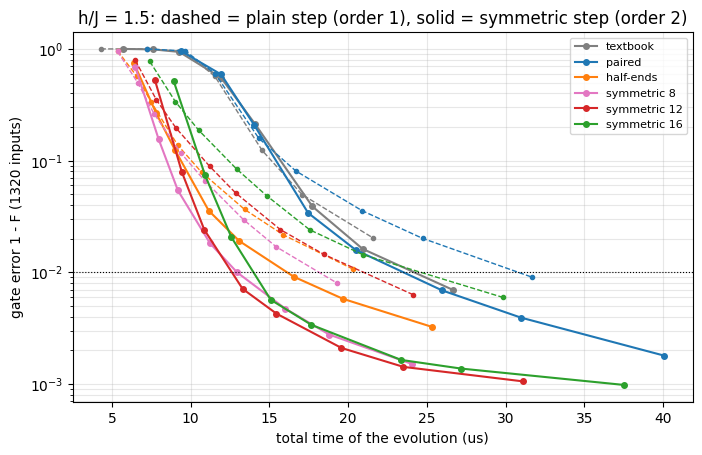

       train  steps  time_us_order1  time_us_order2  time_ratio  infidelity_order1  infidelity_order2  error_ratio
    textbook     12            9.63            11.9        1.24              0.948              0.552         1.72
    textbook     24            14.5            17.7        1.22              0.123             0.0389         3.17
      paired     12            14.3            17.5        1.22              0.158              0.034         4.65
      paired     24            20.9              26        1.24             0.0356            0.00688         5.17
   half-ends     12            9.17            11.2        1.22              0.138             0.0356         3.87
   half-ends     24            13.4            16.6        1.23             0.0365            0.00912            4
 symmetric 8     12             9.4            11.2        1.19              0.116             0.0182         6.39
 symmetric 8     24            13.4              16         1.2             0.02

In [12]:
order1 = lattice_runs(1, [H_MAIN])
order1.to_csv("results/resonant_trains_order1.csv", index=False)
order2 = lattice[lattice.h_over_J == H_MAIN]

fig, ax = plt.subplots(figsize=(8, 4.8))
for name in TRAINS:
    d1, d2 = order1[order1.train == name], order2[order2.train == name]
    ax.plot(d1.time_us, d1.infidelity, "o--", color=COLORS[name], ms=3, lw=1)
    ax.plot(d2.time_us, d2.infidelity, "o-", color=COLORS[name], ms=4, label=name)
ax.axhline(0.01, color="k", lw=0.8, ls=":")
ax.set_yscale("log"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_xlabel("total time of the evolution (us)"); ax.set_ylabel("gate error 1 - F (1320 inputs)")
ax.set_title("h/J = 1.5: dashed = plain step (order 1), solid = symmetric step (order 2)")
plt.show()

compare = order1.merge(order2, on=["train", "steps"], suffixes=("_order1", "_order2"))
compare["time_ratio"] = compare.time_us_order2 / compare.time_us_order1
compare["error_ratio"] = compare.infidelity_order1 / compare.infidelity_order2
print(compare[compare.steps.isin([12, 24])][["train", "steps", "time_us_order1", "time_us_order2", "time_ratio",
                                             "infidelity_order1", "infidelity_order2", "error_ratio"]]
      .to_string(index=False, float_format=lambda v: f"{v:.3g}"))

**Reading.** At the same number of steps the symmetric step takes 1.17–1.33× longer. At 12 and 24 steps it lowers the gate error 1.7–14.8× (at 4 steps, where every train fails, there is no gain). The gain is largest for the best trains (symmetric 12: 12.6×, symmetric 16: 14.8× at 12 steps). With a poor train, its own error dominates and the better Trotter step helps less. The symmetric step is worth it for every train here: in the summary below it is faster to 1 % in every case.

## 7. Summary: time to reach a given gate error

For each train, the total time at which the lattice gate error first drops below 10 %, 3 % and 1 %, interpolated (log-log) between the simulated step counts. At $h/J=1.5$ the faster of the plain and symmetric step is taken. Conservation columns: at the first simulated step count that reaches 1 %.

In [13]:
def time_to_reach(d, target):
    """Total time where the gate error first drops below target, log-log interpolated between simulated points."""
    d = d.sort_values("time_us").reset_index(drop=True)
    below = np.flatnonzero(d.infidelity.values <= target)
    if len(below) == 0:
        return np.nan
    i = below[0]
    if i == 0:
        return d.time_us[0]
    x0, x1 = np.log(d.time_us[i - 1]), np.log(d.time_us[i])
    y0, y1 = np.log(d.infidelity[i - 1]), np.log(d.infidelity[i])
    return float(np.exp(x0 + (np.log(target) - y0) * (x1 - x0) / (y1 - y0)))


rows = []
for h in H_OVER_J:
    for name in TRAINS:
        runs = {2: lattice[(lattice.train == name) & (lattice.h_over_J == h)]}
        if h == H_MAIN:
            runs[1] = order1[order1.train == name]
        row = {"h/J": h, "train": name}
        for target in (0.1, 0.03, 0.01):
            times = {order: time_to_reach(d, target) for order, d in runs.items()}
            order = min(times, key=lambda o: np.inf if np.isnan(times[o]) else times[o])
            row[f"time to {target:.0%} (us)"] = "-" if np.isnan(times[order]) else f"{times[order]:.1f} (order {order})"
        at = runs[2][runs[2].infidelity <= 0.01].sort_values("steps")
        if len(at):
            r = at.iloc[0]
            row.update({"first steps <= 1%": int(r.steps), "gate error there": f"{r.infidelity:.4f}",
                        "Gauss loss there": f"{r.gauss_lost:.1e}", "number loss there": f"{r.number_lost:.1e}"})
        rows.append(row)
summary = pd.DataFrame(rows).fillna("-")
summary.to_csv("results/resonant_trains_summary.csv", index=False)
summary

,h/J,train,time to 10% (us),time to 3% (us),time to 1% (us),first steps <= 1%,gate error there,Gauss loss there,number loss there
0,0.5,textbook,15.2 (order 2),17.7 (order 2),22.5 (order 2),48,0.0060,1.8e-04,1.8e-04
1,0.5,paired,14.8 (order 2),17.1 (order 2),22.9 (order 2),24,0.0067,3.6e-05,5.0e-06
2,0.5,half-ends,8.6 (order 2),10.4 (order 2),13.3 (order 2),24,0.0050,2.5e-03,2.5e-03
3,0.5,symmetric 8,7.8 (order 2),9.9 (order 2),12.9 (order 2),16,0.0100,8.6e-04,8.3e-04
4,0.5,symmetric 12,7.7 (order 2),9.1 (order 2),11.5 (order 2),12,0.0062,5.6e-05,2.8e-05
5,0.5,symmetric 16,8.9 (order 2),9.9 (order 2),11.4 (order 2),8,0.0063,8.4e-05,2.1e-05
6,1.5,textbook,15.1 (order 1),18.6 (order 2),24.0 (order 2),48,0.0069,4.5e-04,4.4e-04
7,1.5,paired,15.3 (order 2),17.9 (order 2),23.3 (order 2),24,0.0069,4.7e-05,1.3e-05
8,1.5,half-ends,9.3 (order 2),11.6 (order 2),16.1 (order 2),24,0.0091,5.6e-03,5.6e-03
9,1.5,symmetric 8,8.5 (order 2),10.2 (order 2),12.9 (order 2),16,0.0100,8.1e-04,7.9e-04


## 8. The recommended step, drawn to scale, and its flat times

**Reading the flat times:** with $r_{\rm eff}$ = 5 ns, the outer train's first and last pulses have zero flat time (they sit at $A_{\min}$). If the measured $r_{\rm eff}$ is larger than 5 ns, those pulses cannot be played at this scale and the trains must be re-optimised with the new $A_{\min}$ (`optimise_trains.py symmetric` after changing `RAMP`); the cell stops with an error in that case.

Symmetric 12, 12 steps: inner train $\theta=\pi/24$ on Q2, outer train $\pi/48$ on Q1 and Q3 together. One isolated step is drawn with both half R_x slots; in the full evolution neighbouring half R_x share one slot.

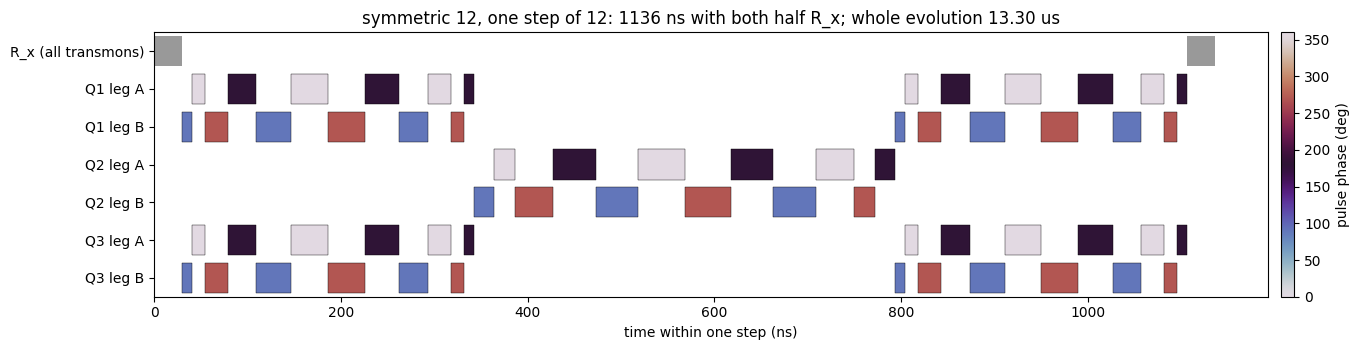

         train  theta  pulse leg  area_rad  phase_deg  flat_ns
    inner (Q2) 0.1309      1   B    0.1067       90.0    11.98
    inner (Q2) 0.1309      2   A    0.1084        0.0    12.26
    inner (Q2) 0.1309      3   B    0.2265      270.0    31.05
    inner (Q2) 0.1309      4   A    0.2536      180.0    35.36
    inner (Q2) 0.1309      5   B    0.2547       90.0    35.54
    inner (Q2) 0.1309      6   A    0.2806        0.0    39.66
    inner (Q2) 0.1309      7   B    0.2806      270.0    39.66
    inner (Q2) 0.1309      8   A    0.2547      180.0    35.54
    inner (Q2) 0.1309      9   B    0.2536       90.0    35.36
    inner (Q2) 0.1309     10   A    0.2265        0.0    31.05
    inner (Q2) 0.1309     11   B    0.1084      270.0    12.26
    inner (Q2) 0.1309     12   A    0.1067      180.0    11.98
outer (Q1, Q3) 0.0654      1   B    0.0314       90.0     0.00
outer (Q1, Q3) 0.0654      2   A    0.0609        0.0     4.69
outer (Q1, Q3) 0.0654      3   B    0.1205      270.0  

In [14]:
def draw_step(name, steps):
    theta = J_T / steps
    rows = ["R_x (all transmons)"] + [f"Q{link + 1} leg {leg}" for link in range(3) for leg in "AB"]
    y = {row: i for i, row in enumerate(rows)}            # numeric row positions, so each label stays on its own pulses
    fig, ax = plt.subplots(figsize=(15, 3.6))
    ax.barh(y[rows[0]], 1e3 * rt.PI_PULSE, left=0, color="0.6")
    t = rt.PI_PULSE
    for links, angle in (((0, 2), theta / 2), ((1,), theta), ((0, 2), theta / 2)):      # outer, inner, outer
        for leg, area, phase in TRAIN[name, angle]:
            length = rt.pulse_length(area)
            for link in links:
                ax.barh(y[f"Q{link + 1} leg {leg}"], 1e3 * length, left=1e3 * t, color=phase_colour(phase), edgecolor="k", lw=0.3)
            t += length
    ax.barh(y[rows[0]], 1e3 * rt.PI_PULSE, left=1e3 * t, color="0.6")
    t += rt.PI_PULSE
    ax.set_yticks(range(len(rows)), rows); ax.set_ylim(len(rows) - 0.5, -0.5)
    ax.set_xlabel("time within one step (ns)")
    total = rt.lattice_time(TRAIN[name, theta], TRAIN[name, theta / 2], 2, steps)
    ax.set_title(f"{name}, one step of {steps}: {1e3 * t:.0f} ns with both half R_x; whole evolution {total:.2f} us")
    fig.colorbar(plt.cm.ScalarMappable(cmap=CMAP, norm=plt.Normalize(0, 360)), ax=ax, label="pulse phase (deg)", pad=0.01)
    fig.tight_layout(); plt.show()


draw_step("symmetric 12", 12)

R_EFF_NS = 5.0                                    # effective ramp offset: area = g (flat + R_EFF). Put the measured value here.
rows = []
for label, theta in (("inner (Q2)", J_T / 12), ("outer (Q1, Q3)", J_T / 24)):
    for i, (leg, area, phase) in enumerate(TRAIN["symmetric 12", theta]):
        flat_ns = 1e3 * area / rt.G - R_EFF_NS
        assert flat_ns >= -1e-9, "this R_EFF would need a negative flat time: re-optimise with the new A_min"
        rows.append(dict(train=label, theta=round(theta, 4), pulse=i + 1, leg=leg, area_rad=round(area, 4),
                         phase_deg=round(np.degrees(phase) % 360, 1), flat_ns=round(flat_ns, 2)))
flat_times = pd.DataFrame(rows)
flat_times.to_csv("results/resonant_trains_symmetric12_flat_times.csv", index=False)
print(flat_times.to_string(index=False))

## Conclusions

All numbers are from the tables above (`results/resonant_trains_*.csv`). Ideal and lossless; complete 8-photon input space; echo on; $JT=\pi/2$; $h/J=1.5$ unless stated.

1. **Use symmetric 12.** It reaches 1 % lattice gate error in about half the time of today's paired train (12 steps, 13.3 µs vs 24 steps, 26.0 µs), with the same Gauss loss (4.7×10⁻⁵). Time to 1 %: symmetric 12 12.6 µs, symmetric 8 12.9, symmetric 16 13.9, half-ends 16.1, paired 23.3, textbook 24.0 µs. At $h/J=0.5$ symmetric 12 and 16 are fastest (11.5, 11.4 µs; paired 22.9). At $h/J=3$ symmetric 8 is fastest (14.1 µs) but loses 6×10⁻⁴ to Gauss; symmetric 12 takes 15.9 µs.
2. **Symmetric 16** when conservation matters most at 12 steps: Gauss 2.1×10⁻⁵, number 6.8×10⁻⁶, 15.1 µs.
3. **The best trains found are mirror-symmetric.** The best free train (from the symmetric paired start) is a 12-pulse `+ + − −` train with mirror-symmetric areas; randomly kicked, less symmetric starts end worse. Imposing that shape reproduces it with 6 numbers per angle and beats the best free 12-pulse train. This is the best of the starts tried, not a proof that symmetry is optimal.
4. **Why the symmetric trains conserve well:** for one hop at θ = π/24 only 1.7 % (symmetric 12) and 0.3 % (symmetric 16) of their one-hop error is a transmon flip. The rest is a slightly wrong hop, which costs fidelity but not photon number.
5. **Their limit:** beyond 12 steps their Gauss loss stays at 4–10×10⁻⁵, while paired falls to 2×10⁻⁶ at 48 steps (40 µs).
6. **Always use the symmetric Trotter step:** 1.17–1.33× the time per step, 12.6× (symmetric 12) and 14.8× (symmetric 16) lower error at 12 steps.
7. **Single link:** CSWAP above 99 % in 2.2–2.3 µs (symmetric 12, outer 2 steps or inner 4 steps; symmetric 16, inner 3 steps), 99.9 % in 3.7 µs (symmetric 16, outer 4 steps). Paired: 99.1 % in 4.3 µs.
8. **Calibration:** $g$ to well below 1 %, $r_{\rm eff}$ to better than 0.25 ns, and leg phases to well below 2° for 1 % gate error; these common errors leave Gauss's law intact. Random pulse-to-pulse errors (2° phase, 2 % area) break it at the 10⁻²–10⁻¹ level.

**Not included:** transmon f level, loss, dephasing, χ/Kerr, pulse shapes, real calibration data.